In [3]:
import numpy as np
import matplotlib.pyplot as plt
import scqubits as scq

L_prime=400e-9
C_prime=160e-12
length=10e-3

velocity=1/(np.sqrt(L_prime*C_prime))
Z0=np.sqrt(L_prime/C_prime)
print(velocity)
print(Z0)

125000000.00000001
50.0


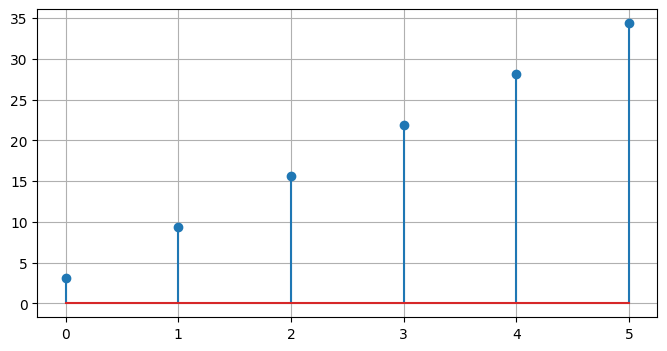

In [4]:
n_modes=6
n=np.arange(n_modes)
frequencies=(2*n+1)*velocity/(4*length)
frequencies_GHZ=frequencies/1e9
plt.figure(figsize=(8,4))
plt.stem(n,frequencies_GHZ)
plt.grid(True)
plt.show()

In [5]:
f_r_GHz=frequencies_GHZ[0]
resonator=scq.Oscillator(
    E_osc=f_r_GHz,
    truncated_dim=10
)
energies_GHz=resonator.eigenvals()
print(np.round(energies_GHz,4))

[ 0.     3.125  6.25   9.375 12.5   15.625]


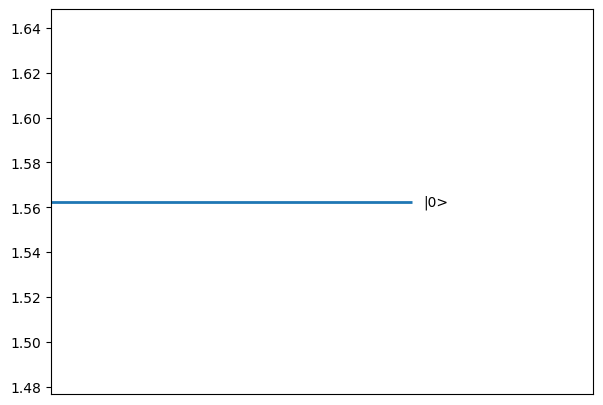

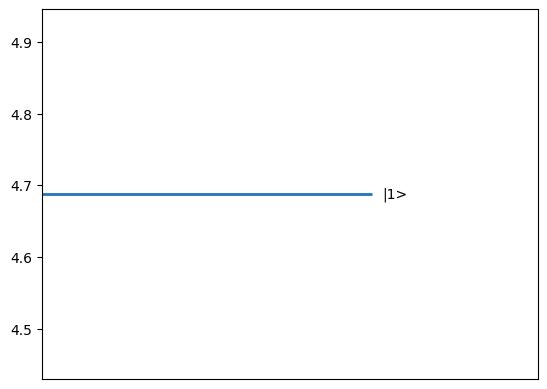

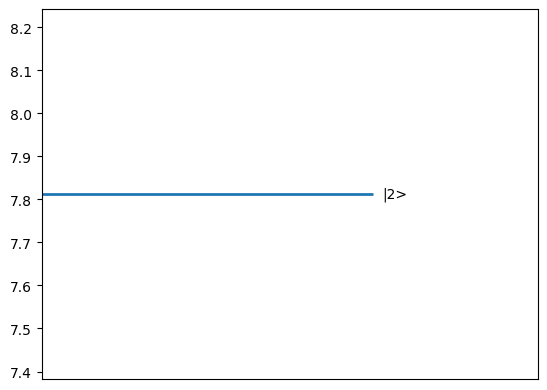

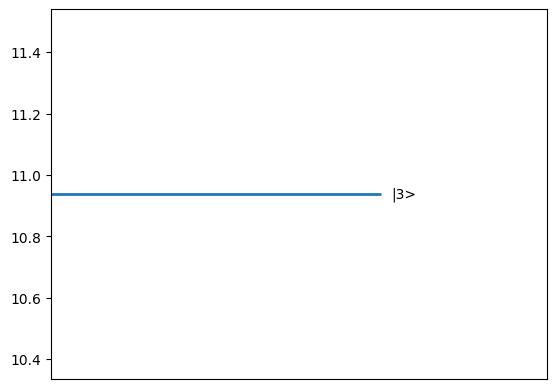

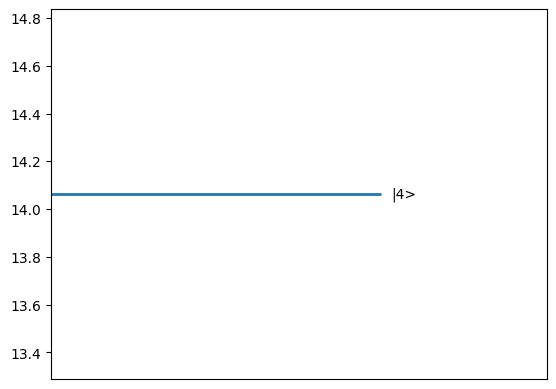

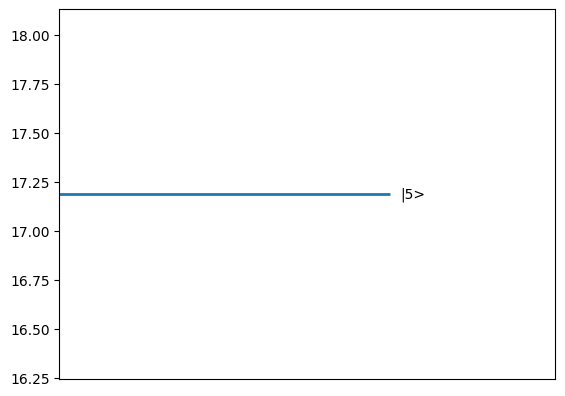

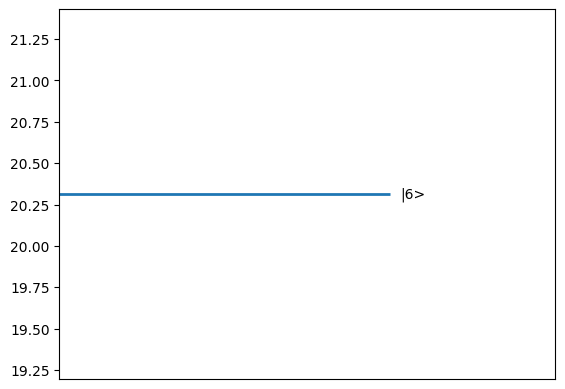

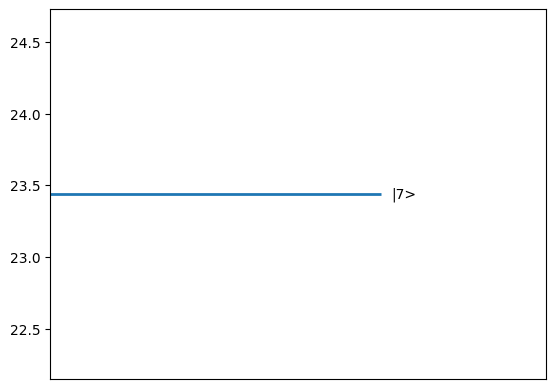

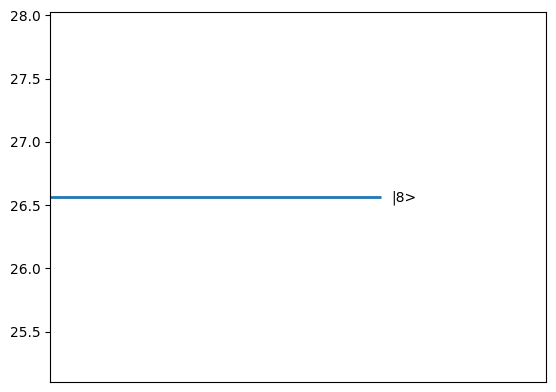

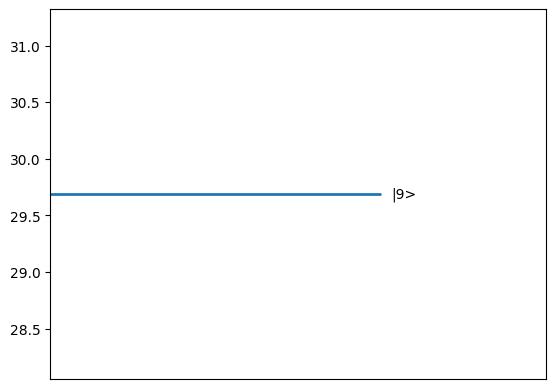

In [6]:
levels=np.arange(10)
E_over_h_GHz=f_r_GHz*(levels+0.5)
plt.figure(figsize=(7,5))
for m,energy in zip(levels,E_over_h_GHz):
  plt.hlines(energy,0,1,linewidth=2)
  plt.text(1.03,energy,f"|{m}>",va="center")
  plt.xlim(0,1.5)
  plt.xticks([])
  plt.show()

In [12]:
from scipy.linalg import eigvals
wr=2*np.pi*f_r_GHz
qubit=scq.Transmon(EJ=20.0,EC=0.25,ng=0.0,ncut=35)
qubit_energies=qubit.eigenvals(evals_count=3)
fq=qubit_energies[1]-qubit_energies[0]
g=0.08
N=8
a=np.diag(np.sqrt(np.arange(1,N)),1)
adag=a.conj().T
Iq=np.eye(2)
Ir=np.eye(N)
Hq=np.diag([0.0,fq])
Hr=f_r_GHz*(adag@a)
sm=np.array([[0,1],[0,0]],dtype=complex)
sp=sm.conj().T
H=(
    np.kron(Hq,Ir)+
    np.kron(Iq,Hr)+g*(np.kron(sp,a)+np.kron(sm,adag))
)
E=np.linalg.eigvalsh(H)
print(np.round(E[:8],4))

[ 0.      3.1228  6.0656  6.2457  9.1928  9.3685 12.32   12.4913]


level 0: bare = 0.0000  dressed = 0.0000  shift = +0.00 MHz
level 1: bare = 3.1250  dressed = 3.1228  shift = -2.18 MHz
level 2: bare = 6.0635  dressed = 6.0656  shift = +2.18 MHz
level 3: bare = 6.2500  dressed = 6.2457  shift = -4.35 MHz
level 4: bare = 9.1885  dressed = 9.1928  shift = +4.35 MHz
level 5: bare = 9.3750  dressed = 9.3685  shift = -6.52 MHz
level 6: bare = 12.3135  dressed = 12.3200  shift = +6.52 MHz
level 7: bare = 12.5000  dressed = 12.4913  shift = -8.69 MHz


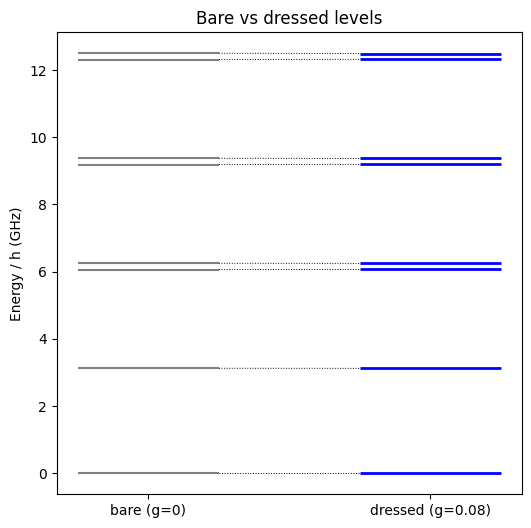

In [14]:
bare=np.sort([q*fq + m*f_r_GHz for q in [0,1] for m in range(N)])[:8]

plt.figure(figsize=(6,6))
for i in range(8):
  plt.hlines(bare[i],0,1,color="gray")
  plt.hlines(E[i],2,3,color="blue",linewidth=2)
  plt.plot([1,2],[bare[i],E[i]],"k:",linewidth=0.7)
  print(f"level {i}: bare = {bare[i]:.4f}  dressed = {E[i]:.4f}  shift = {(E[i]-bare[i])*1000:+.2f} MHz")
plt.xticks([0.5,2.5],["bare (g=0)","dressed (g=0.08)"])
plt.ylabel("Energy / h (GHz)")
plt.title("Bare vs dressed levels")
plt.show()

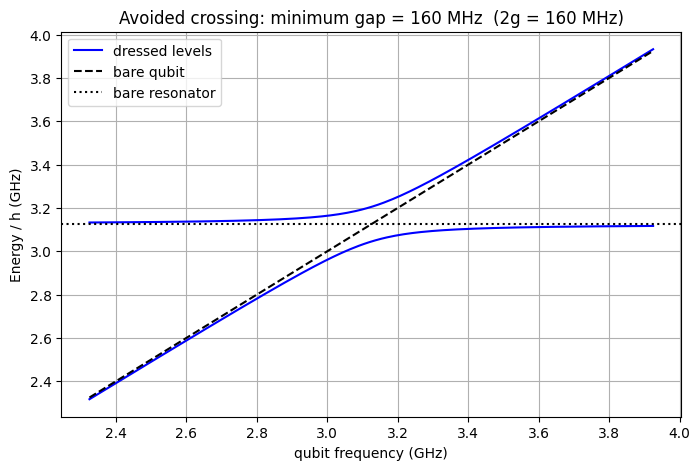

In [15]:
fq_values=np.linspace(f_r_GHz-0.8,f_r_GHz+0.8,200)
level1=[]
level2=[]
for f in fq_values:
  Hq_s=np.diag([0.0,f])
  H_s=np.kron(Hq_s,Ir)+np.kron(Iq,f_r_GHz*(adag@a))+g*(np.kron(sp,a)+np.kron(sm,adag))
  E_s=np.linalg.eigvalsh(H_s)
  level1.append(E_s[1])
  level2.append(E_s[2])

plt.figure(figsize=(8,5))
plt.plot(fq_values,level1,"b",label="dressed levels")
plt.plot(fq_values,level2,"b")
plt.plot(fq_values,fq_values,"k--",label="bare qubit")
plt.axhline(f_r_GHz,color="k",linestyle=":",label="bare resonator")
plt.xlabel("qubit frequency (GHz)")
plt.ylabel("Energy / h (GHz)")
plt.title(f"Avoided crossing: minimum gap = {min(np.array(level2)-np.array(level1))*1000:.0f} MHz  (2g = {2*g*1000:.0f} MHz)")
plt.legend()
plt.grid(True)
plt.show()

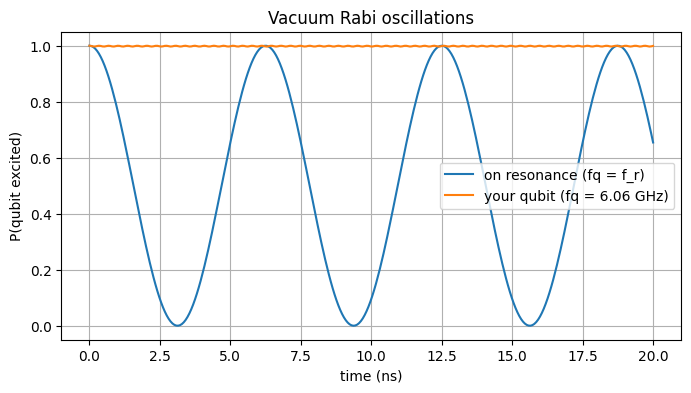

In [16]:
from scipy.linalg import expm

psi0=np.kron([0,1],np.eye(N)[0])           # |e> ⊗ |0>
Pe=np.kron(np.diag([0,1]),Ir)               # projector: qubit excited
times=np.linspace(0,20,300)                  # ns

H_res=np.kron(np.diag([0.0,f_r_GHz]),Ir)+np.kron(Iq,f_r_GHz*(adag@a))+g*(np.kron(sp,a)+np.kron(sm,adag))

P_res=[]
P_yours=[]
for t in times:
  psi_r=expm(-1j*2*np.pi*H_res*t)@psi0
  psi_y=expm(-1j*2*np.pi*H*t)@psi0
  P_res.append(np.real(psi_r.conj()@Pe@psi_r))
  P_yours.append(np.real(psi_y.conj()@Pe@psi_y))

plt.figure(figsize=(8,4))
plt.plot(times,P_res,label="on resonance (fq = f_r)")
plt.plot(times,P_yours,label=f"your qubit (fq = {fq:.2f} GHz)")
plt.xlabel("time (ns)")
plt.ylabel("P(qubit excited)")
plt.title("Vacuum Rabi oscillations")
plt.legend()
plt.grid(True)
plt.show()

resonator freq, qubit in |g>: 3.1228 GHz
resonator freq, qubit in |e>: 3.1272 GHz
chi from E      = 2.17 MHz
chi = g^2/Delta = 2.18 MHz


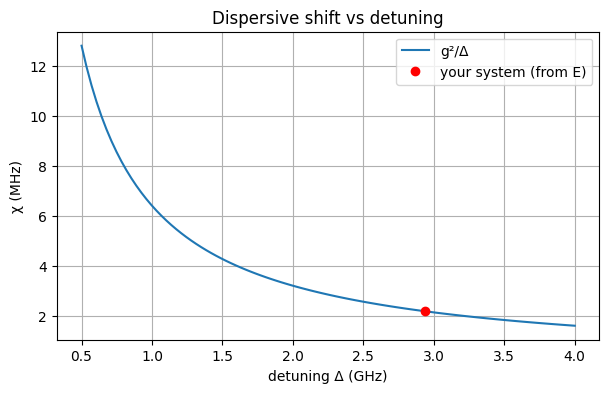

In [17]:
fr_g=E[1]-E[0]
fr_e=E[4]-E[2]
Delta=fq-f_r_GHz
chi_num=(fr_e-fr_g)/2
chi_theory=g**2/Delta
print(f"resonator freq, qubit in |g>: {fr_g:.4f} GHz")
print(f"resonator freq, qubit in |e>: {fr_e:.4f} GHz")
print(f"chi from E      = {chi_num*1000:.2f} MHz")
print(f"chi = g^2/Delta = {chi_theory*1000:.2f} MHz")

Delta_values=np.linspace(0.5,4,100)
plt.figure(figsize=(7,4))
plt.plot(Delta_values,g**2/Delta_values*1000,label="g²/Δ")
plt.plot(Delta,chi_num*1000,"ro",label="your system (from E)")
plt.xlabel("detuning Δ (GHz)")
plt.ylabel("χ (MHz)")
plt.title("Dispersive shift vs detuning")
plt.legend()
plt.grid(True)
plt.show()

In [2]:
!pip install scqubits

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 83.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.5/28.5 MB 67.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [scqubits]
